# All trace features in one function: `trace_features.py`

`src/trace_features.py` merges the two earlier feature sets into one function:

* the **39 comparison tools** of `compare_trace.py` (11 fits, 19 skip tools, 5 horizontal, 4 vertical),
  summarised as the median over the usable pixels;
* the **advanced features** of `advanced_trace_features.ipynb` (CDS level, noise character, discrete
  noise, edges, slow structure).

```python
from trace_features import trace_features, FEATURES
result = trace_features(path_or_decoded_trace)
result.scalars   # 85 numbers, one per feature
result.spread    # pixel-to-pixel spread of the per-pixel features
result.curves    # 12 curves (mean shapes, autocorrelation, Allan deviation, spectra, ...)
FEATURES[name]   # unit, description, why a model might use it
```

`process_packet.py` now calls this function for every trace, so every packet's dataset row has all
85 features for each of its 6 trace sets (mean, scatter between sets, θ − reference difference).

**Any trace geometry and timing.** The function works for any number of rows, columns and skips, any
binning and any clock delays. Every count it uses scales with the trace, and a feature that cannot
exist for a trace is NaN. Section 8 runs it on synthetic traces of very different shapes.

The earlier files are unchanged and kept for reference: `compare_trace.py`,
`trace_comparison_walkthrough*.ipynb` and `advanced_trace_features.ipynb`. Every feature is described in
`docs/trace_features.tex`.

**Contents:** 1. the registry · 2. all features of one trace · 3. the curves · 4. traces with missing
features · 5. redundancy between features · 6. which features separate amplifiers better than repeats
· 7. from features to the dataset · 8. any trace geometry and timing

In [1]:
import sys, itertools, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from trace_features import trace_features, FEATURES, scalar_names, ALLAN_N, SAMPLE_RATE_HZ, TRUE_PERIOD
from decode_trace import decode_trace

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SESSION = PROJECT / "data" / "2026-10-08-PA03_PQ04_traces"
def traces_of(ch, board=101):
    return sorted(SESSION.glob(f"trace_*_ch{ch}_{board}_*.RJ45ADCDATA{ch}"))

## 1. The registry

Every feature has an entry in `FEATURES` with its group (the name prefix), unit, description, the
reason a model might use it, whether it is a number or a curve, and where it comes from.

In [2]:
groups = {}
for name, f in FEATURES.items():
    groups.setdefault((f.origin, f.group), {"scalar": 0, "curve": 0})[f.kind] += 1
print(f"{'origin':11s} {'group':11s} {'numbers':>8s} {'curves':>7s}")
for (origin, group), n in groups.items():
    print(f"{origin:11s} {group:11s} {n['scalar']:8d} {n['curve']:7d}")
print(f"{'total':23s} {sum(n['scalar'] for n in groups.values()):8d} {sum(n['curve'] for n in groups.values()):7d}")
print("\nexample entry:", FEATURES["noise: reset-level scatter (ADU)"])

origin      group        numbers  curves
comparison  fit               11       0
comparison  skip              17       2
comparison  horizontal         4       1
comparison  vertical           3       1
advanced    level              5       1
advanced    noise             15       5
advanced    discrete           7       0
advanced    edge              15       2
advanced    slow               8       0
total                         85      12

example entry: Feature(group='noise', unit='ADU', description="Skip-to-skip standard deviation of each cycle's pedestal-window level after removing the slow droop (polynomial across skips at each sample position). Each reset sets a new random level; the CDS cancels it.", link='sense node (kTC) and reset gate; related to the gain', kind='scalar', origin='advanced')


## 2. All features of one trace

The trace used throughout: module 101, channel 0, 2026-10-08, first repeat. `trace_features` reads
the `.meta` next to the file (for the clock swings used by the per-volt features). It raises an error
for a trace with lost data.

In [3]:
PATH = traces_of(0)[0]
t0 = time.time()
result = trace_features(PATH)
print(f"{PATH.name}: {len(result.scalars)} numbers and {len(result.curves)} curves in {time.time() - t0:.2f} s")
print("usable pixels:", result.info["pixels_used"], "| row-start pixels:", result.info["row_start_pixels"],
      "| charged pixels:", result.info["charged_pixels"])

trace_2x5x500_20x20_ch0_101_20261008_185447_12.RJ45ADCDATA0: 85 numbers and 12 curves in 0.29 s
usable pixels: [1, 2, 3, 4, 6, 7, 8, 9] | row-start pixels: [0, 5] | charged pixels: []


In [4]:
current = None
for name in scalar_names():
    f = FEATURES[name]
    if f.group != current:
        current = f.group
        print(f"\n--- {f.group} ({f.origin}) " + "-" * 60)
    value = result.scalars[name]
    spread = result.spread.get(name)
    extra = f"  ± {spread:.3g} (pixel spread)" if spread is not None and np.isfinite(spread) else ""
    print(f"{name:52s} {value:12.5g} {f.unit:14s}{extra}")


--- fit (comparison) ------------------------------------------------------------
fit: settling time after pulse (us)                       0.61692 µs              ± 0.000549 (pixel spread)
fit: settling amplitude after pulse                         43085 ADU             ± 35.4 (pixel spread)
fit: dip recovery time (us)                               0.30464 µs              ± 0.0003 (pixel spread)
fit: dip recovery amplitude                                -12099 ADU             ± 10.6 (pixel spread)
fit: baseline droop time constant (skips)                  236.11 skips           ± 1.02 (pixel spread)
fit: baseline droop amplitude                              -17962 ADU             ± 273 (pixel spread)
fit: first-skip ringing frequency (cyc/skip)              0.23313 cycles/skip     ± 0.0023 (pixel spread)
fit: first-skip ringing decay (skips)                      2.1932 skips           ± 0.147 (pixel spread)
fit: first-skip ringing amplitude                          201.52 ADU        

The pixel spread is shown for features computed per pixel. Small spreads relative to the value
(e.g. the fit time constants, jitter, reset-level scatter) mean the feature is well defined within
one trace.

## 3. The curves

The 12 curves are fixed-length vectors. A model can use them directly, or through a few summary
numbers (most of which are among the scalars).

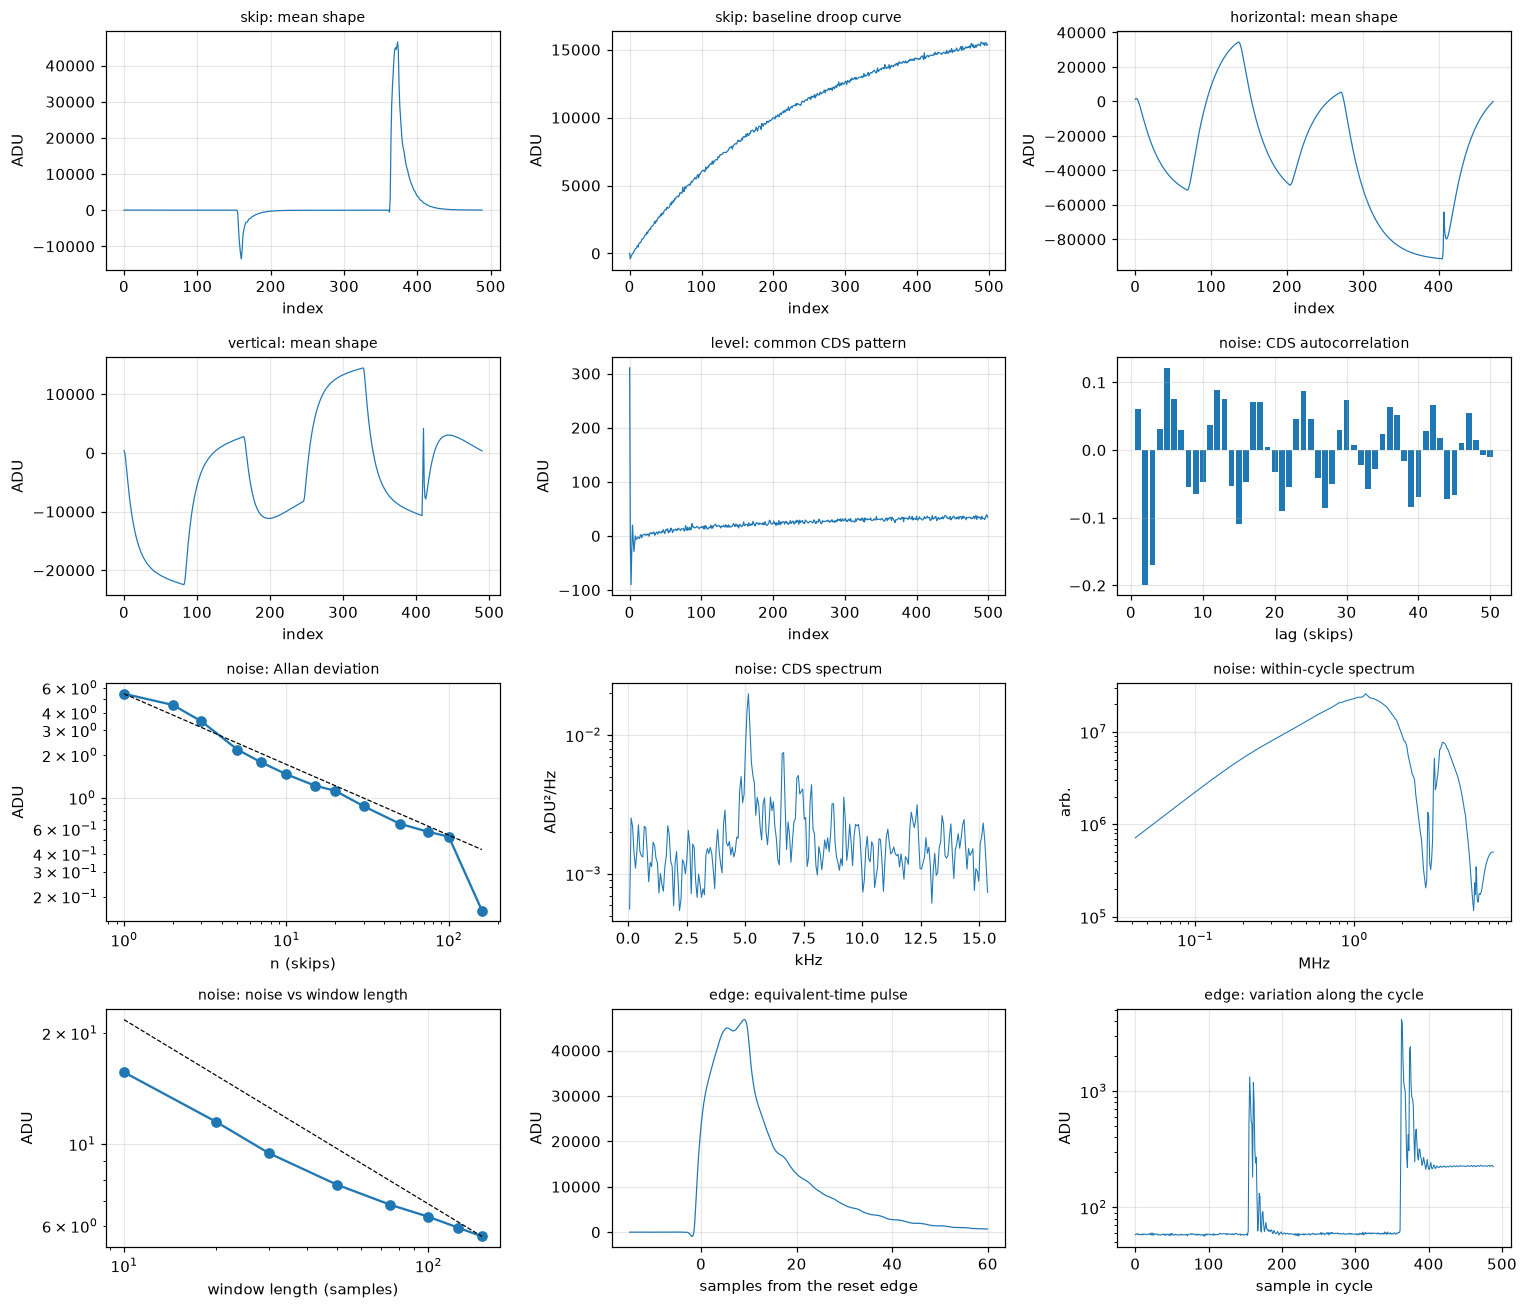

In [5]:
names = list(result.curves)
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, name in zip(axes.ravel(), names):
    y = np.asarray(result.curves[name], float)
    if name == "noise: Allan deviation":
        ax.loglog(ALLAN_N, y, "o-"); ax.loglog(ALLAN_N, y[0] / np.sqrt(ALLAN_N), "k--", lw=0.8); ax.set_xlabel("n (skips)")
    elif name == "noise: noise vs window length":
        L = np.array([10, 20, 30, 50, 75, 100, 125, 150]); ax.loglog(L, y, "o-"); ax.loglog(L, y[-1] * np.sqrt(150 / L), "k--", lw=0.8); ax.set_xlabel("window length (samples)")
    elif name == "noise: CDS spectrum":
        f = np.fft.rfftfreq(490, TRUE_PERIOD / SAMPLE_RATE_HZ); ax.semilogy(f[1:len(y)] / 1e3, y[1:], lw=0.7); ax.set_xlabel("kHz")
    elif name == "noise: within-cycle spectrum":
        f = np.fft.rfftfreq(357, 1 / SAMPLE_RATE_HZ); ax.loglog(f[1:] / 1e6, y[1:], lw=0.7); ax.set_xlabel("MHz")
    elif name == "noise: CDS autocorrelation":
        ax.bar(np.arange(1, len(y) + 1), y); ax.set_xlabel("lag (skips)")
    elif name == "edge: equivalent-time pulse":
        ax.plot(np.arange(-15, 60, 0.1)[:len(y)] + 0.05, y, lw=0.8); ax.set_xlabel("samples from the reset edge")
    elif name == "edge: variation along the cycle":
        ax.semilogy(y, lw=0.7); ax.set_xlabel("sample in cycle")
    else:
        ax.plot(y, lw=0.8); ax.set_xlabel("index")
    ax.set_title(name, fontsize=9); ax.set_ylabel(FEATURES[name].unit)
plt.tight_layout(); plt.show()

## 4. Traces where some features are missing (NaN)

A feature is NaN when it cannot exist for that trace. The model must accept missing values, or the
feature must be left out:

* **charge loss and charged-pixel skewness**: only when a pixel holds more than 1000 ADU of charge;
* **vertical tools**: when no vertical transfer can be found (e.g. a trace whose first row's block is cut);
* **per-volt feedthrough**: without the `.meta` (clock swings).

In [6]:
examples = {"ch0 repeat 1": traces_of(0)[0], "ch0 repeat 4 (charged pixel)": traces_of(0)[3]}
for label, path in examples.items():
    r = trace_features(path)
    missing = [k for k, v in r.scalars.items() if not np.isfinite(v)]
    print(f"{label:30s} charged pixels {r.info['charged_pixels']}, NaN features: {missing}")
    if r.info["charged_pixels"]:
        print(f"{'':30s} charge-loss slope {r.scalars['level: charge-loss slope (%)']:+.2f} %")
try:
    trace_features(traces_of(0)[2])
except ValueError as err:
    print(f"{'ch0 repeat 3 (damaged)':30s} refused: {str(err)[:70]}...")

ch0 repeat 1                   charged pixels [], NaN features: ['level: charge-loss slope (%)', 'level: charged-pixel skewness']


ch0 repeat 4 (charged pixel)   charged pixels [0], NaN features: []
                               charge-loss slope -2.83 %
ch0 repeat 3 (damaged)         refused: trace has quality problems: ['5 pedestal windows have an unusual lengt...


## 5. Redundancy between features

Several features measure related things, e.g. the old "CDS rms (detrended)" and the white-noise fit,
or the old "noise of 50-skip average" and the new Allan deviation at n = 50. Redundant features are
harmless for tree models and regularised linear models, but they inflate the apparent number of
inputs and can confuse feature importances.

The test: compute every feature on all 19 healthy traces of the 2026-10-08 session (4 channels × 5
repeats, minus the damaged one). Then list the pairs whose values are almost perfectly correlated
across these traces (|r| > 0.98). With 19 traces from 4 amplifiers, a high correlation mostly
reflects that both features track the same amplifier difference. That is a hint of redundancy, not
proof; the scan will show whether they also move together with θ.

In [7]:
session = {}
for ch in range(4):
    for path in traces_of(ch):
        try:
            session[(ch, path.name)] = trace_features(path).scalars
        except ValueError:
            pass                                             # the damaged repeat
names = [n for n in scalar_names() if all(np.isfinite(s[n]) for s in session.values())]
X = np.array([[s[n] for n in names] for s in session.values()])
print(f"{len(session)} traces, {len(names)} features defined on all of them "
      f"(left out: {[n for n in scalar_names() if n not in names]})")
R = np.corrcoef(X.T)
pairs = [(names[i], names[j], R[i, j]) for i in range(len(names)) for j in range(i + 1, len(names)) if abs(R[i, j]) > 0.98]
print(f"\n{len(pairs)} pairs with |r| > 0.98, e.g.:")
for a, b, r_ in sorted(pairs, key=lambda x: -abs(x[2]))[:25]:
    print(f"  {r_:+.3f}  {a}  <->  {b}")

19 traces, 83 features defined on all of them (left out: ['level: charge-loss slope (%)', 'level: charged-pixel skewness'])

73 pairs with |r| > 0.98, e.g.:
  -1.000  skip: signal-window level  <->  skip: CDS mean (skips>=10)
  +1.000  skip: dip height  <->  edge: dip per volt SW (ADU/V)
  +1.000  fit: white noise per skip (ADU)  <->  skip: CDS rms (detrended)
  +0.999  horizontal: minimum  <->  vertical: minimum
  +0.999  skip: CDS rms (detrended)  <->  skip: noise power 0.1-1 MHz
  +0.999  fit: white noise per skip (ADU)  <->  skip: noise power 0.1-1 MHz
  +0.999  skip: noise of 10-skip average  <->  skip: noise power 0.1-1 MHz
  +0.999  skip: noise of 50-skip average  <->  noise: Allan deviation n=50 (ADU)
  +0.998  fit: white noise per skip (ADU)  <->  skip: noise of 10-skip average
  +0.998  skip: CDS rms (detrended)  <->  skip: noise of 10-skip average
  -0.998  slow: PC1 variance fraction  <->  slow: PC2 variance fraction
  +0.997  skip: CDS rms (detrended)  <->  edge: ringing r

/private/tmp/claude-501/-Users-dylanrosenmerkel-Documents-Software-ccd-opt-ml/0face8dd-3b86-44b8-b894-2b5f02a97511/scratchpad/venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/private/tmp/claude-501/-Users-dylanrosenmerkel-Documents-Software-ccd-opt-ml/0face8dd-3b86-44b8-b894-2b5f02a97511/scratchpad/venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


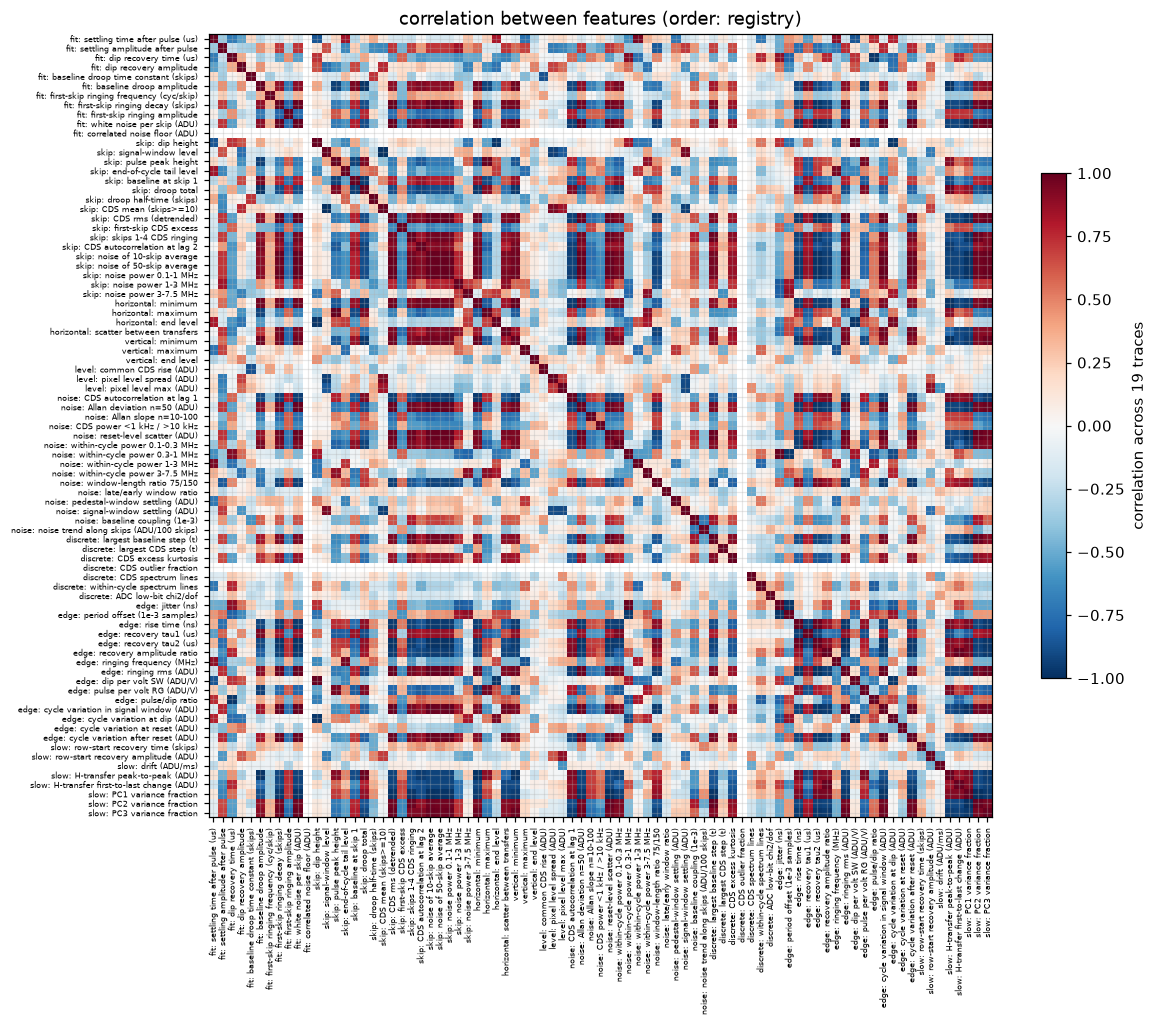

In [8]:
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=90, fontsize=5); ax.set_yticklabels(names, fontsize=5)
plt.colorbar(im, ax=ax, shrink=0.6, label="correlation across 19 traces")
ax.set_title("correlation between features (order: registry)"); plt.tight_layout(); plt.show()

## 6. Which features separate amplifiers better than repeats?

The same test as before, now for all 85 features and **all 6 pairs of channels**: for each pair,
separation = |mean(A) − mean(B)| / pooled standard deviation of the repeats. A feature counts as
"separating" a pair when the separation is ≥ 3. Summarised per feature:

* the **number of channel pairs** (out of 6) it separates;
* the **median separation** over the 6 pairs.

A feature that separates many amplifier pairs is precise compared with its repeat scatter, the
precondition for seeing a parameter change.

In [9]:
by_channel = {ch: np.array([[s[n] for n in scalar_names()] for (c, _), s in session.items() if c == ch]) for ch in range(4)}
all_names = scalar_names()
sep = np.full((len(all_names), 6), np.nan)
for k, (a, b) in enumerate(itertools.combinations(range(4), 2)):
    A, B = by_channel[a], by_channel[b]
    with np.errstate(invalid="ignore", divide="ignore"):
        pooled = np.sqrt((np.nanvar(A, 0, ddof=1) * (len(A) - 1) + np.nanvar(B, 0, ddof=1) * (len(B) - 1)) / (len(A) + len(B) - 2))
        sep[:, k] = np.where(pooled > 0, np.abs(np.nanmean(A, 0) - np.nanmean(B, 0)) / pooled, np.nan)   # 0 scatter: undefined
n_sep = np.sum(sep >= 3, axis=1); med = np.nanmedian(sep, axis=1)
order = np.argsort(-np.nan_to_num(med, nan=-1))
print(f"{'feature':52s} {'pairs ≥ 3':>9s} {'median sep.':>11s}")
for i in order:
    print(f"{all_names[i]:52s} {n_sep[i]:9d} {med[i]:11.1f}")

feature                                              pairs ≥ 3 median sep.
edge: ringing frequency (MHz)                                6       293.3
edge: recovery tau2 (us)                                     6       120.4
horizontal: minimum                                          6       114.4
edge: ringing rms (ADU)                                      6        99.1
edge: recovery amplitude ratio                               6        79.9
fit: settling time after pulse (us)                          6        52.8
horizontal: maximum                                          6        38.1
slow: H-transfer peak-to-peak (ADU)                          6        34.4
vertical: minimum                                            6        31.6
edge: cycle variation at dip (ADU)                           6        27.6
skip: noise power 1-3 MHz                                    6        21.0
edge: pulse/dip ratio                                        6        20.1
edge: cycle variation in 

/var/folders/8r/9580jb0n0bl6x89mtdgghsr80000gn/T/ipykernel_45895/3383893793.py:7: RuntimeWarning: Degrees of freedom <= 0 for slice.
  pooled = np.sqrt((np.nanvar(A, 0, ddof=1) * (len(A) - 1) + np.nanvar(B, 0, ddof=1) * (len(B) - 1)) / (len(A) + len(B) - 2))
/var/folders/8r/9580jb0n0bl6x89mtdgghsr80000gn/T/ipykernel_45895/3383893793.py:8: RuntimeWarning: Mean of empty slice
  sep[:, k] = np.where(pooled > 0, np.abs(np.nanmean(A, 0) - np.nanmean(B, 0)) / pooled, np.nan)   # 0 scatter: undefined
/var/folders/8r/9580jb0n0bl6x89mtdgghsr80000gn/T/ipykernel_45895/3383893793.py:9: RuntimeWarning: All-NaN slice encountered
  n_sep = np.sum(sep >= 3, axis=1); med = np.nanmedian(sep, axis=1)


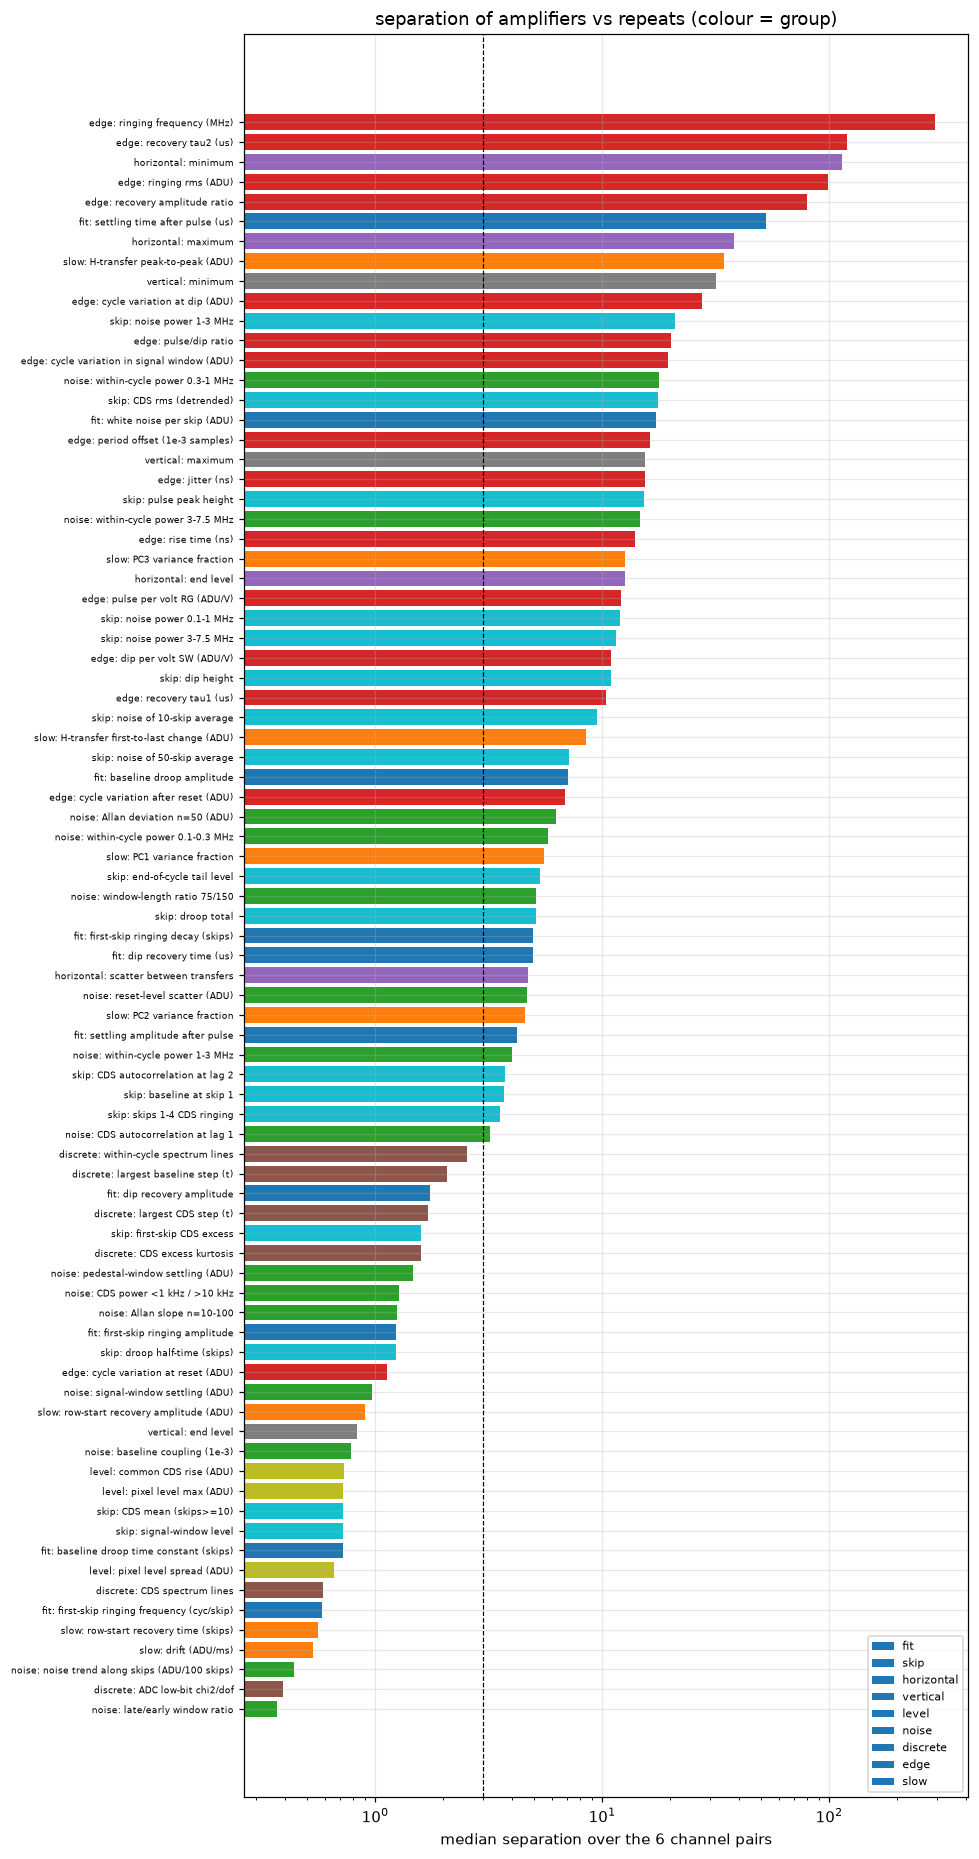

18 features separate all 6 pairs; 24 separate none


In [10]:
colors = {"fit": "tab:blue", "skip": "tab:cyan", "horizontal": "tab:purple", "vertical": "tab:gray",
          "level": "tab:olive", "noise": "tab:green", "discrete": "tab:brown", "edge": "tab:red", "slow": "tab:orange"}
valid = [i for i in order if np.isfinite(med[i])]
fig, ax = plt.subplots(figsize=(9, 17))
ax.barh([all_names[i] for i in valid][::-1], [med[i] for i in valid][::-1],
        color=[colors[FEATURES[all_names[i]].group] for i in valid][::-1])
ax.axvline(3, color="k", ls="--", lw=0.8)
ax.set_xscale("log"); ax.tick_params(axis="y", labelsize=6)
ax.set(xlabel="median separation over the 6 channel pairs", title="separation of amplifiers vs repeats (colour = group)")
for g, c in colors.items():
    ax.barh([], [], color=c, label=g)
ax.legend(loc="lower right", fontsize=7); plt.tight_layout(); plt.show()
print(f"{np.sum(n_sep == 6)} features separate all 6 pairs; {np.sum(n_sep == 0)} separate none")

How to read this:

* features near the top are precise, amplifier-specific numbers; they are the best candidates to also
  see changes in the operating parameters;
* features near the bottom are either the same on every amplifier, or too variable between repeats.
  The baseline coupling, for example, is the same on all channels. If it moved with θ, it would be a
  clean signal; that only the scan can show;
* the charge-related features vary between back-to-back runs (the charge in the pixels changed). The
  flushes before every trace set in a packet are meant to stabilise them.

These are 19 traces from one session and one module. The packets' 3 + 3 trace sets will measure the
repeat scatter of every feature in every packet, which is the noise level the model should use.

## 7. From features to the dataset

`process_packet.py` calls `trace_features` on every trace of a packet, then:

* `combine_repeats` averages each feature over the 3 trace sets at θ, and over the 3 at the
  reference, ignoring NaN, and keeps the scatter between sets;
* `trace_differences` takes θ − reference per board and channel;
* `dataset.csv` gets, per (packet, board, channel), the columns `trace.<feature>`,
  `trace_sd.<feature>`, `ref.<feature>`, `ref_sd.<feature>` and `diff.<feature>`, next to `theta.*`,
  `delta.*` and the WADERs labels `label.*`. The curves are saved in each trace's `.npz` file
  (`curve: <name>`).

Below: the trace-feature columns of the processed rehearsal packet, if it exists (run
`process_packet_walkthrough.ipynb` or `python src/process_packet.py` first).

In [11]:
import csv
dataset = PROJECT / "rehearsal" / "processed" / "dataset.csv"
if dataset.exists():
    rows = list(csv.DictReader(open(dataset)))
    cols = rows[0].keys()
    for prefix in ("theta.", "delta.", "label.", "trace.", "trace_sd.", "ref.", "ref_sd.", "diff."):
        print(f"{prefix:10s} {sum(c.startswith(prefix) for c in cols):4d} columns")
    if sum(c.startswith("diff.") for c in cols) < 85:
        print("this dataset was built before the merge: rerun process_packet.py to refresh it")
else:
    print("no processed rehearsal packet found")

theta.       33 columns
delta.        1 columns
label.       12 columns
trace.       86 columns
trace_sd.    85 columns
ref.         86 columns
ref_sd.      85 columns
diff.        85 columns


## 8. Any trace geometry and timing

All real traces so far share one geometry (2×5 pixels, 500 skips, 20×20 binning, reference timing). To
show the function works for others, `src/simulate_trace.py` writes synthetic traces in the real file
format for any geometry and sequencer delays, with a `.meta`. Their waveform is only a rough imitation
of the real one, so the feature *values* are not physics. What matters here is that the layout is found
correctly and the features are computed.

How the analysis finds the layout:

* **pixels**: from the order of the pedestal and signal windows (a pixel ends with its extra pedestal
  window). The pixel number in the inline records has only 4 bits and repeats after 16 pixels, so it
  is not used;
* **skip cycle**: from the spacing of the pedestal windows (its exact, non-integer length);
* **transfers**: horizontal from flag bit 6, vertical from bit 7. Flag glitches shorter than 10
  samples are ignored;
* **row starts**: from `NCOL` in the `.meta`, or from the vertical transfers without it;
* **cross-check**: the `.meta` layout (`trace_geometry.py`) is compared with what is found, and any
  mismatch is a warning.

`python src/check_trace_analysis.py` runs 25 such configurations with all the checks. Below are a few.

In [12]:
import json, tempfile
from simulate_trace import simulate_trace
from trace_regions import split_regions

configs = {
    "reference (2x5, 500 skips, 20x20)": {},
    "1 skip": dict(NDCM=1),
    "20 skips": dict(NDCM=20),
    "3x7 = 21 pixels, 100 skips": dict(NROW=3, NCOL=7, NDCM=100),
    "1 column, 4 rows": dict(NROW=4, NCOL=1),
    "no binning (1x1)": dict(NSBIN=1, NPBIN=1),
    "short windows (delayInt 200)": dict(delayInt=200),
    "slow H clocks, 100 skips": dict(delay_Ha=6000, delay_Hb=6000, delay_Hc=6000, NDCM=100),
    "mixed": dict(NROW=3, NCOL=7, NDCM=37, NSBIN=3, NPBIN=2, delayInt=700, delay_Ha=900, delay_Hb=900,
                  delay_Hc=900, delay_Va=3000, delay_Vb=3000, delaySWL=500),
}
tmp = Path(tempfile.mkdtemp())
print(f"{'configuration':36s} {'pixels':>6s} {'skips':>5s} {'window':>6s} {'cycle':>7s} {'H/pixel':>7s} {'V':>4s} {'rows':14s} {'warn':>4s} {'NaN':>4s}")
for name, params in configs.items():
    path = simulate_trace(tmp / name.split(" ")[0], seed=1, **params)
    meta = json.loads(path.with_suffix(".meta").read_text())
    r = split_regions(decode_trace(path), meta)
    f = trace_features(path)
    n_nan = sum(not np.isfinite(v) for v in f.scalars.values())
    print(f"{name:36s} {r.n_pixels:6d} {r.n_skips:5d} {r.n_ped:6d} {r.period_exact:7.1f} {max(len(h) for h in r.h):7d} "
          f"{0 if r.v is None else len(r.v):4d} {str(r.row_starts)[:14]:14s} {len(r.warnings):4d} {n_nan:4d}")

configuration                        pixels skips window   cycle H/pixel    V rows           warn  NaN


reference (2x5, 500 skips, 20x20)        10   500    150   488.7      20   19 [0, 5]            0    2
1 skip                                   10     1    150   489.0      20   19 [0, 5]            0   50
20 skips                                 10    20    150   488.7      20   19 [0, 5]            0    9


3x7 = 21 pixels, 100 skips               21   100    150   488.7      20   19 [0, 7, 14]        0    5


1 column, 4 rows                          4   500    150   488.7      20   19 [0, 1, 2, 3]      0    4


no binning (1x1)                         10   500    150   488.7       1    1 [0, 5]            0    4


short windows (delayInt 200)             10   500     30   248.7      20   19 [0, 5]            0    2


slow H clocks, 100 skips                 10   100    150   488.7      20   19 [0, 5]            0    5


mixed                                    21    37    105   421.2       3    2 [0, 7, 14]        0    5


Every configuration is decoded with the right number of pixels, skips, window length, cycle length,
transfers and row starts, with no warnings. The NaN column counts features that cannot exist for that
trace:

* with 1 skip, all noise and timing features;
* with 20 or 100 skips, the noise of 50-skip averages and the Allan deviation at n = 50;
* with one column, the row-start recovery (no ordinary pixel follows a row start);
* without binning, the scatter between horizontal transfers (there is only one).

The two charge-loss features are NaN unless a pixel holds charge, as for the real traces.